In [1]:
# Step 1: Import Libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

sns.set_style("whitegrid")

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
# Step 2: Load Datasets

orders = pd.read_csv("../data/processed/orders_cleaned.csv")
customers = pd.read_csv("../data/raw/olist_customers_dataset.csv")
payments = pd.read_csv("../data/raw/olist_order_payments_dataset.csv")

print("DATASETS LOADED SUCCESSFULLY")

print("Orders:", orders.shape)
print("Customers:", customers.shape)
print("Payments:", payments.shape)

DATASETS LOADED SUCCESSFULLY
Orders: (99441, 12)
Customers: (99441, 5)
Payments: (103886, 5)


In [3]:
# Step 3: Prepare Customer Data

# Aggregate payment records at order level
order_payments = (
    payments.groupby("order_id")
    .agg(total_payment=("payment_value", "sum"))
    .reset_index()
)

# Keep only delivered orders
delivered_orders = orders[
    orders["order_status"] == "delivered"
].copy()

# Merge customer information
customer_orders = delivered_orders.merge(
    customers[
        ["customer_id", "customer_unique_id", "customer_state"]
    ],
    on="customer_id",
    how="left",
    validate="many_to_one"
)

# Merge payment information
customer_orders = customer_orders.merge(
    order_payments,
    on="order_id",
    how="left",
    validate="one_to_one"
)

print("CUSTOMER DATA PREPARED")
print("Delivered orders:", len(customer_orders))
print("Unique customers:", customer_orders["customer_unique_id"].nunique())
print("Missing customer IDs:", customer_orders["customer_unique_id"].isna().sum())
print("Missing payment values:", customer_orders["total_payment"].isna().sum())

display(customer_orders.head())

CUSTOMER DATA PREPARED
Delivered orders: 96478
Unique customers: 93358
Missing customer IDs: 0
Missing payment values: 1


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,delivery_date_issue,order_approved_at_missing,order_delivered_carrier_date_missing,order_delivered_customer_date_missing,customer_unique_id,customer_state,total_payment
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,False,0,0,0,7c396fd4830fd04220f754e42b4e5bff,SP,38.71
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13,False,0,0,0,af07308b275d755c9edb36a90c618231,BA,141.46
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04,False,0,0,0,3a653a41f6f9fc3d2a113cf8398680e8,GO,179.12
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15,False,0,0,0,7c142cf63193a1473d2e66489a9ae977,RN,72.20
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26,False,0,0,0,72632f0f9dd73dfee390c9b22eb56dd6,SP,28.62


In [4]:
# Step 4: Check Missing Payment Record

missing_payment_order = customer_orders[
    customer_orders["total_payment"].isna()
]

print("Orders with missing payment:")
display(
    missing_payment_order[
        ["order_id", "customer_unique_id", "customer_state"]
    ]
)

print("Number of affected customers:",
      missing_payment_order["customer_unique_id"].nunique())

Orders with missing payment:


,order_id,customer_unique_id,customer_state
29811,bfbd0f9bdef84302105ad712db648a6c,830d5b7aaa3b6f1e9ad63703bec97d23,SP


Number of affected customers: 1


In [5]:
# Step 5: Customer-Level Analysis

customer_spending = (
    customer_orders
    .groupby("customer_unique_id")
    .agg(
        total_orders=("order_id", "nunique"),
        lifetime_spending=("total_payment", lambda x: x.sum(min_count=1)),
        customer_state=("customer_state", "first")
    )
    .reset_index()
)

print("CUSTOMER-LEVEL DATA CREATED")
print("Total unique customers:", len(customer_spending))
print("Customers with missing spending:",
      customer_spending["lifetime_spending"].isna().sum())

display(customer_spending.head())

CUSTOMER-LEVEL DATA CREATED
Total unique customers: 93358
Customers with missing spending: 1


,customer_unique_id,total_orders,lifetime_spending,customer_state
0,0000366f3b9a7992bf8c76cfdf3221e2,1,141.90,SP
1,0000b849f77a49e4a4ce2b2a4ca5be3f,1,27.19,SP
2,0000f46a3911fa3c0805444483337064,1,86.22,SC
3,0000f6ccb0745a6a4b88665a16c9f078,1,43.62,PA
4,0004aac84e0df4da2b147fca70cf8255,1,196.89,SP


In [6]:
# Step 6: Customer Purchase Frequency Analysis

total_customers = customer_spending["customer_unique_id"].nunique()

one_time_customers = (
    customer_spending["total_orders"] == 1
).sum()

repeat_customers = (
    customer_spending["total_orders"] > 1
).sum()

repeat_percentage = repeat_customers / total_customers * 100

print("CUSTOMER PURCHASE FREQUENCY")
print("-" * 40)

print("Total unique customers:", total_customers)
print("One-time customers:", one_time_customers)
print("Repeat customers:", repeat_customers)

print(f"Repeat customer percentage: {repeat_percentage:.2f}%")

# Orders per customer distribution
order_frequency = (
    customer_spending["total_orders"]
    .value_counts()
    .sort_index()
)

print("\nORDERS PER CUSTOMER DISTRIBUTION")
display(order_frequency)

CUSTOMER PURCHASE FREQUENCY
----------------------------------------
Total unique customers: 93358
One-time customers: 90557
Repeat customers: 2801
Repeat customer percentage: 3.00%

ORDERS PER CUSTOMER DISTRIBUTION


total_orders
1     90557
2      2573
3       181
4        28
5         9
6         5
7         3
9         1
15        1
Name: count, dtype: int64

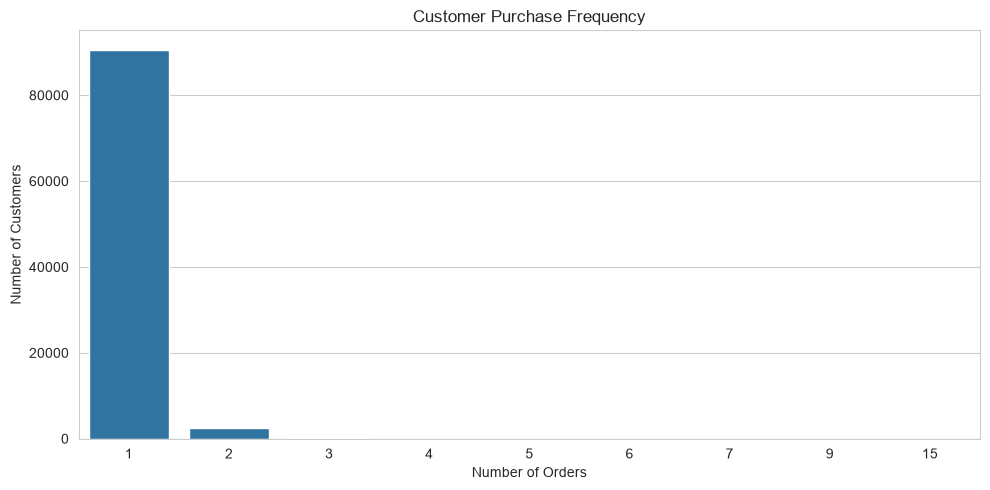

In [7]:
# Step 7: Purchase Frequency Visualization

plt.figure(figsize=(10, 5))

sns.barplot(
    x=order_frequency.index,
    y=order_frequency.values
)

plt.title("Customer Purchase Frequency")
plt.xlabel("Number of Orders")
plt.ylabel("Number of Customers")

plt.tight_layout()
plt.show()

In [8]:
# Step 8: Customer Spending Analysis

valid_spending = customer_spending["lifetime_spending"].dropna()

print("CUSTOMER SPENDING ANALYSIS")
print("-" * 40)

print("Average spending: R$", round(valid_spending.mean(), 2))
print("Median spending: R$", round(valid_spending.median(), 2))
print("Minimum spending: R$", round(valid_spending.min(), 2))
print("Maximum spending: R$", round(valid_spending.max(), 2))

print("\nSPENDING DISTRIBUTION")
display(valid_spending.describe())

CUSTOMER SPENDING ANALYSIS
----------------------------------------
Average spending: R$ 165.2
Median spending: R$ 107.78
Minimum spending: R$ 9.59
Maximum spending: R$ 13664.08

SPENDING DISTRIBUTION


count    93357.000000
mean       165.198772
std        226.314579
min          9.590000
25%         63.060000
50%        107.780000
75%        182.560000
max      13664.080000
Name: lifetime_spending, dtype: float64

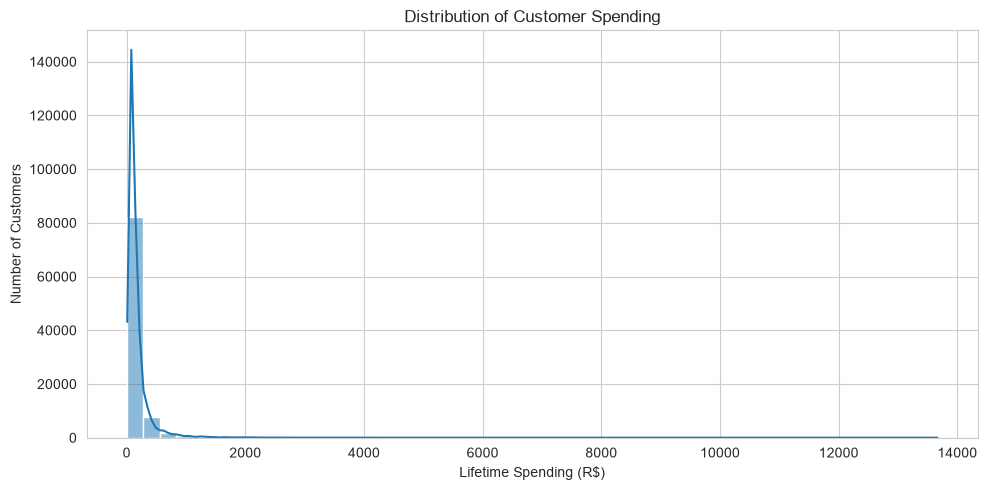

In [9]:
# Step 9: Customer Spending Distribution

plt.figure(figsize=(10, 5))

sns.histplot(
    valid_spending,
    bins=50,
    kde=True
)

plt.title("Distribution of Customer Spending")
plt.xlabel("Lifetime Spending (R$)")
plt.ylabel("Number of Customers")

plt.tight_layout()
plt.show()

In [10]:
# Step 10: Top 10 Highest-Spending Customers

top_customers = (
    customer_spending
    .dropna(subset=["lifetime_spending"])
    .sort_values("lifetime_spending", ascending=False)
    .head(10)
)

print("TOP 10 HIGHEST-SPENDING CUSTOMERS")

display(
    top_customers[
        ["customer_unique_id", "total_orders", "lifetime_spending", "customer_state"]
    ]
)

TOP 10 HIGHEST-SPENDING CUSTOMERS


,customer_unique_id,total_orders,lifetime_spending,customer_state
3724,0a0a92112bd4c708ca5fde585afaa872,1,13664.08,RJ
79636,da122df9eeddfedc1dc1f5349a1a690c,2,7571.63,RJ
43168,763c8b1c9c68a0229c42c9fc6f662b93,1,7274.88,ES
80463,dc4802a71eae9be1dd28f5d788ceb526,1,6929.31,MS
25436,459bef486812aa25204be022145caa62,1,6922.21,ES
93081,ff4159b92c40ebe40454e3e6a7c35ed6,1,6726.66,SP
23411,4007669dec559734d6f53e029e360987,1,6081.54,MG
87148,eebb5dda148d3893cdaf5b5ca3040ccb,1,4764.34,SP
26640,48e1ac109decbb87765a3eade6854098,1,4681.78,PB
73127,c8460e4251689ba205045f3ea17884a1,4,4655.91,RS


In [11]:
# Step 11: Customer Spending Segmentation

customer_spending["customer_segment"] = pd.qcut(
    customer_spending["lifetime_spending"],
    q=4,
    labels=["Low Value", "Medium Value", "High Value", "Top Value"]
)

segment_analysis = (
    customer_spending
    .dropna(subset=["lifetime_spending"])
    .groupby("customer_segment", observed=True)
    .agg(
        customers=("customer_unique_id", "count"),
        average_spending=("lifetime_spending", "mean"),
        total_spending=("lifetime_spending", "sum")
    )
)

segment_analysis["customer_percentage"] = (
    segment_analysis["customers"] /
    segment_analysis["customers"].sum() * 100
).round(2)

segment_analysis["spending_percentage"] = (
    segment_analysis["total_spending"] /
    segment_analysis["total_spending"].sum() * 100
).round(2)

print("CUSTOMER SPENDING SEGMENTATION")
display(segment_analysis.round(2))

CUSTOMER SPENDING SEGMENTATION


,customers,average_spending,total_spending,customer_percentage,spending_percentage
customer_segment,,,,,
Low Value,23341,43.60,1017564.74,25.0,6.60
Medium Value,23339,83.56,1950106.85,25.0,12.64
High Value,23338,140.98,3290093.62,25.0,21.33
Top Value,23339,392.68,9164696.56,25.0,59.42


In [12]:
# Step 12: RFM Analysis

customer_orders["order_purchase_timestamp"] = pd.to_datetime(
    customer_orders["order_purchase_timestamp"],
    errors="coerce"
)

rfm_data = customer_orders.dropna(
    subset=["order_purchase_timestamp"]
).copy()

reference_date = (
    rfm_data["order_purchase_timestamp"].max()
    + pd.Timedelta(days=1)
)

rfm = (
    rfm_data
    .groupby("customer_unique_id")
    .agg(
        last_purchase=("order_purchase_timestamp", "max"),
        frequency=("order_id", "nunique"),
        monetary=("total_payment", lambda x: x.sum(min_count=1))
    )
    .reset_index()
)

rfm["recency"] = (
    reference_date - rfm["last_purchase"]
).dt.days

print("RFM DATASET")
print("-" * 40)
print("Total customers:", len(rfm))
print("Reference date:", reference_date)
print("\nRFM SUMMARY")

display(
    rfm[["recency", "frequency", "monetary"]].describe().round(2)
)

print("Customers with missing monetary value:", rfm["monetary"].isna().sum())

RFM DATASET
----------------------------------------
Total customers: 93358
Reference date: 2018-08-30 15:00:37

RFM SUMMARY


,recency,frequency,monetary
count,93358.00,93358.00,93357.00
mean,237.94,1.03,165.20
std,152.59,0.21,226.31
min,1.00,1.00,9.59
25%,114.00,1.00,63.06
50%,219.00,1.00,107.78
75%,346.00,1.00,182.56
max,714.00,15.00,13664.08


Customers with missing monetary value: 1


In [13]:
# Step 12: Calculate RFM Scores

rfm = rfm_data.copy()

# Recency: lower days = better score
rfm["R_score"] = pd.qcut(
    rfm["recency"].rank(method="first"),
    q=5,
    labels=[5, 4, 3, 2, 1]
).astype(int)

# Frequency: custom thresholds because most customers have one order
rfm["F_score"] = pd.cut(
    rfm["frequency"],
    bins=[0, 1, 2, 4, 9, float("inf")],
    labels=[1, 2, 3, 4, 5]
).astype(int)

# Monetary: higher spending = better score
rfm["M_score"] = pd.qcut(
    rfm["monetary"].rank(method="first"),
    q=5,
    labels=[1, 2, 3, 4, 5]
).astype("Int64")

print("RFM SCORES CREATED")
display(rfm.head())

print("\nRFM SCORE DISTRIBUTION")
display(rfm[["R_score", "F_score", "M_score"]].describe())

KeyError: 'recency'

In [14]:
print("RFM dataset columns:")
print(rfm_data.columns.tolist())

print("\nFirst 5 rows:")
display(rfm_data.head())

RFM dataset columns:
['order_id', 'customer_id', 'order_status', 'order_purchase_timestamp', 'order_approved_at', 'order_delivered_carrier_date', 'order_delivered_customer_date', 'order_estimated_delivery_date', 'delivery_date_issue', 'order_approved_at_missing', 'order_delivered_carrier_date_missing', 'order_delivered_customer_date_missing', 'customer_unique_id', 'customer_state', 'total_payment']

First 5 rows:


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,delivery_date_issue,order_approved_at_missing,order_delivered_carrier_date_missing,order_delivered_customer_date_missing,customer_unique_id,customer_state,total_payment
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,False,0,0,0,7c396fd4830fd04220f754e42b4e5bff,SP,38.71
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13,False,0,0,0,af07308b275d755c9edb36a90c618231,BA,141.46
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04,False,0,0,0,3a653a41f6f9fc3d2a113cf8398680e8,GO,179.12
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15,False,0,0,0,7c142cf63193a1473d2e66489a9ae977,RN,72.20
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26,False,0,0,0,72632f0f9dd73dfee390c9b22eb56dd6,SP,28.62


In [15]:
# Step 12: Create Customer-Level RFM Dataset

# Ensure purchase timestamp is datetime
customer_orders["order_purchase_timestamp"] = pd.to_datetime(
    customer_orders["order_purchase_timestamp"]
)

# Reference date: one day after the latest purchase
reference_date = (
    customer_orders["order_purchase_timestamp"].max()
    + pd.Timedelta(days=1)
)

# Aggregate data at customer level
rfm_data = (
    customer_orders
    .groupby("customer_unique_id")
    .agg(
        last_purchase=("order_purchase_timestamp", "max"),
        frequency=("order_id", "nunique"),
        monetary=("total_payment", lambda x: x.sum(min_count=1))
    )
    .reset_index()
)

# Calculate recency
rfm_data["recency"] = (
    reference_date - rfm_data["last_purchase"]
).dt.days

print("RFM DATASET CREATED")
print("-" * 40)
print("Total customers:", len(rfm_data))
print("Reference date:", reference_date)

display(rfm_data.head())

RFM DATASET CREATED
----------------------------------------
Total customers: 93358
Reference date: 2018-08-30 15:00:37


,customer_unique_id,last_purchase,frequency,monetary,recency
0,0000366f3b9a7992bf8c76cfdf3221e2,2018-05-10 10:56:27,1,141.90,112
1,0000b849f77a49e4a4ce2b2a4ca5be3f,2018-05-07 11:11:27,1,27.19,115
2,0000f46a3911fa3c0805444483337064,2017-03-10 21:05:03,1,86.22,537
3,0000f6ccb0745a6a4b88665a16c9f078,2017-10-12 20:29:41,1,43.62,321
4,0004aac84e0df4da2b147fca70cf8255,2017-11-14 19:45:42,1,196.89,288


In [16]:
print("RFM SUMMARY")
display(rfm_data[["recency", "frequency", "monetary"]].describe())

print(
    "Customers with missing monetary value:",
    rfm_data["monetary"].isna().sum()
)

RFM SUMMARY


,recency,frequency,monetary
count,93358.000000,93358.000000,93357.000000
mean,237.941773,1.033420,165.198772
std,152.591453,0.209097,226.314579
min,1.000000,1.000000,9.590000
25%,114.000000,1.000000,63.060000
50%,219.000000,1.000000,107.780000
75%,346.000000,1.000000,182.560000
max,714.000000,15.000000,13664.080000


Customers with missing monetary value: 1


In [17]:
# Step 13: Calculate RFM Scores

rfm = rfm_data.copy()

# Recency: more recent = higher score
rfm["R_score"] = pd.qcut(
    rfm["recency"].rank(method="first"),
    q=5,
    labels=[5, 4, 3, 2, 1]
).astype(int)

# Frequency: custom thresholds
rfm["F_score"] = pd.cut(
    rfm["frequency"],
    bins=[0, 1, 2, 4, 9, float("inf")],
    labels=[1, 2, 3, 4, 5]
).astype(int)

# Monetary: higher spending = higher score
rfm["M_score"] = pd.qcut(
    rfm["monetary"].rank(method="first"),
    q=5,
    labels=[1, 2, 3, 4, 5]
).astype("Int64")

print("RFM SCORES CREATED")
display(rfm.head(10))

print("\nRFM SCORE DISTRIBUTION")
display(rfm[["R_score", "F_score", "M_score"]].describe())

RFM SCORES CREATED


,customer_unique_id,last_purchase,frequency,monetary,recency,R_score,F_score,M_score
0,0000366f3b9a7992bf8c76cfdf3221e2,2018-05-10 10:56:27,1,141.90,112,4,1,4
1,0000b849f77a49e4a4ce2b2a4ca5be3f,2018-05-07 11:11:27,1,27.19,115,4,1,1
2,0000f46a3911fa3c0805444483337064,2017-03-10 21:05:03,1,86.22,537,1,1,2
3,0000f6ccb0745a6a4b88665a16c9f078,2017-10-12 20:29:41,1,43.62,321,2,1,1
4,0004aac84e0df4da2b147fca70cf8255,2017-11-14 19:45:42,1,196.89,288,2,1,4
5,0004bd2a26a76fe21f786e4fbd80607f,2018-04-05 19:33:16,1,166.98,146,4,1,4
6,00050ab1314c0e55a6ca13cf7181fecf,2018-04-20 12:57:23,1,35.38,132,4,1,1
7,00053a61a98854899e70ed204dd4bafe,2018-02-28 11:15:41,1,419.18,183,3,1,5
8,0005e1862207bf6ccc02e4228effd9a0,2017-03-04 23:32:12,1,150.12,543,1,1,4
9,0005ef4cd20d2893f0d9fbd94d3c0d97,2018-03-12 15:22:12,1,129.76,170,4,1,3



RFM SCORE DISTRIBUTION


,R_score,F_score,M_score
count,93358.000000,93358.000000,93357.0
mean,3.000000,1.032659,3.0
std,1.414229,0.193276,1.414236
min,1.000000,1.000000,1.0
25%,2.000000,1.000000,2.0
50%,3.000000,1.000000,3.0
75%,4.000000,1.000000,4.0
max,5.000000,5.000000,5.0


In [18]:
# Step 14: Customer Segmentation

def classify_customer(row):

    if row["R_score"] >= 4 and row["F_score"] >= 4:
        return "Champions"

    elif row["F_score"] >= 3:
        return "Loyal Customers"

    elif row["R_score"] >= 4 and row["F_score"] == 1:
        return "Recent One-Time Customers"

    elif row["R_score"] <= 2 and row["F_score"] == 2:
        return "At Risk"

    else:
        return "Others"


rfm["customer_segment"] = rfm.apply(
    classify_customer,
    axis=1
)

print("RFM CUSTOMER SEGMENTS")
print("-" * 40)

display(
    rfm["customer_segment"]
    .value_counts()
    .rename_axis("customer_segment")
    .reset_index(name="customers")
)

RFM CUSTOMER SEGMENTS
----------------------------------------


,customer_segment,customers
0,Others,56070
1,Recent One-Time Customers,36135
2,At Risk,925
3,Loyal Customers,214
4,Champions,14


In [19]:
# Step 15: RFM Segment Performance Analysis

segment_performance = (
    rfm.dropna(subset=["monetary"])
    .groupby("customer_segment")
    .agg(
        customers=("customer_unique_id", "count"),
        average_recency=("recency", "mean"),
        average_frequency=("frequency", "mean"),
        average_spending=("monetary", "mean"),
        total_spending=("monetary", "sum")
    )
    .sort_values("total_spending", ascending=False)
)

segment_performance["customer_percentage"] = (
    segment_performance["customers"] /
    segment_performance["customers"].sum() * 100
).round(2)

segment_performance["spending_percentage"] = (
    segment_performance["total_spending"] /
    segment_performance["total_spending"].sum() * 100
).round(2)

print("RFM SEGMENT PERFORMANCE")
display(segment_performance.round(2))

RFM SEGMENT PERFORMANCE


,customers,average_recency,average_frequency,average_spending,total_spending,customer_percentage,spending_percentage
customer_segment,,,,,,,
Others,56069,330.80,1.03,162.41,9106211.92,60.06,59.05
Recent One-Time Customers,36135,90.41,1.00,164.33,5937936.37,38.71,38.50
At Risk,925,380.78,2.00,284.07,262764.65,0.99,1.70
Loyal Customers,214,209.29,3.21,487.15,104249.12,0.23,0.68
Champions,14,95.07,6.21,807.12,11299.71,0.01,0.07


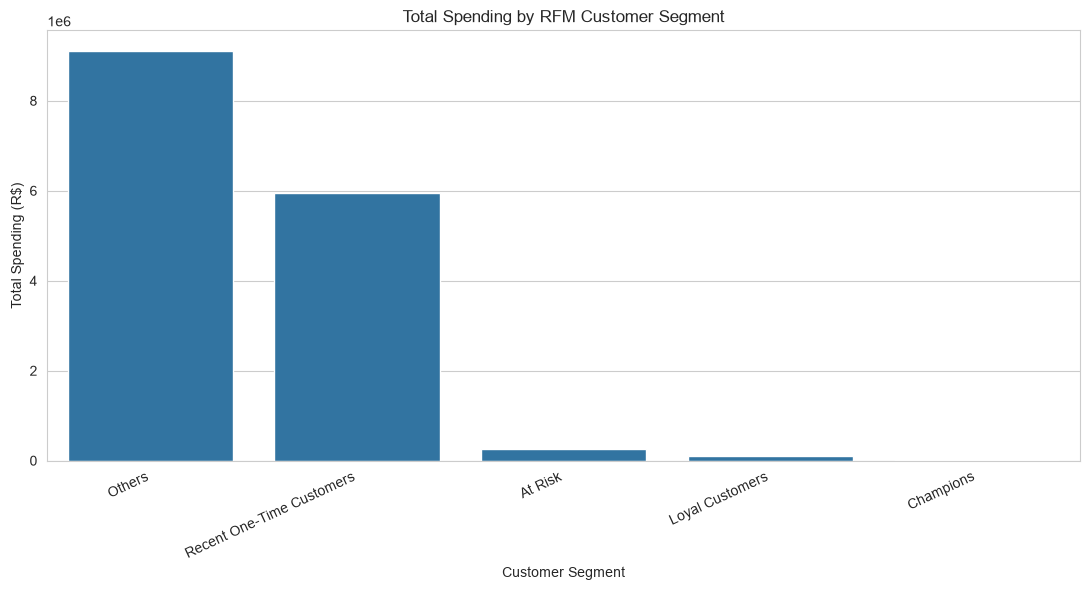

In [20]:
# Step 16: Total Spending by RFM Segment

plt.figure(figsize=(11, 6))

sns.barplot(
    data=segment_performance.reset_index(),
    x="customer_segment",
    y="total_spending"
)

plt.title("Total Spending by RFM Customer Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Total Spending (R$)")
plt.xticks(rotation=25, ha="right")

plt.tight_layout()
plt.show()

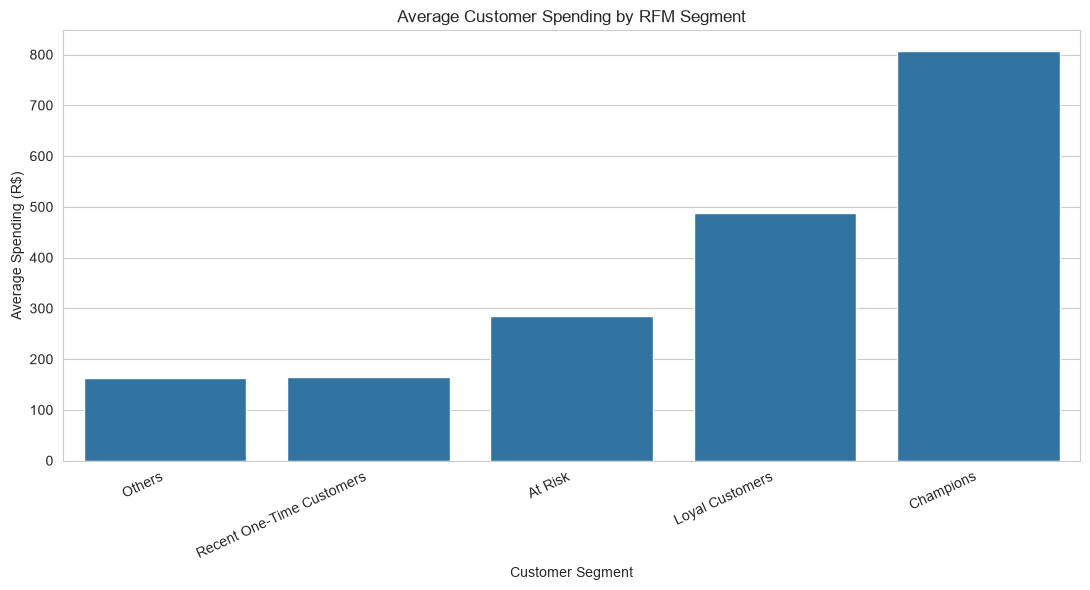

In [21]:
# Step 17: Average Spending by RFM Segment

plt.figure(figsize=(11, 6))

sns.barplot(
    data=segment_performance.reset_index(),
    x="customer_segment",
    y="average_spending"
)

plt.title("Average Customer Spending by RFM Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Average Spending (R$)")
plt.xticks(rotation=25, ha="right")

plt.tight_layout()
plt.show()


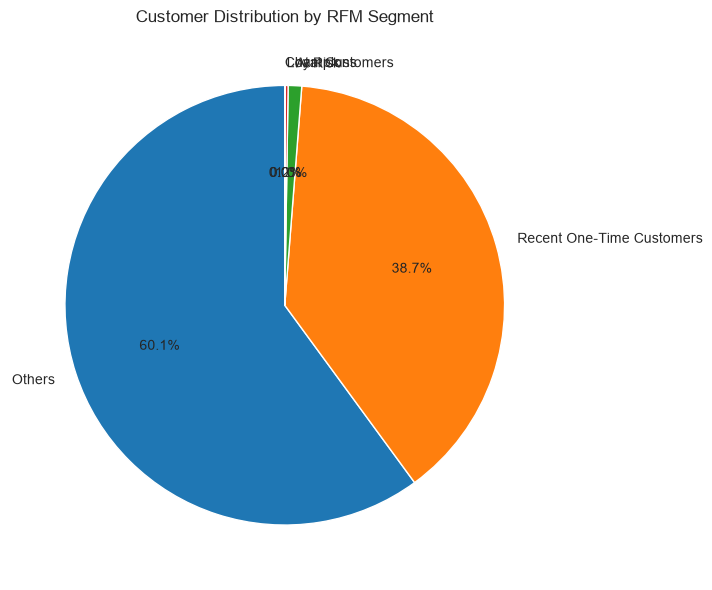

In [22]:
# Step 18: Customer Distribution by RFM Segment

plt.figure(figsize=(9, 6))

segment_counts = rfm["customer_segment"].value_counts()

plt.pie(
    segment_counts,
    labels=segment_counts.index,
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Customer Distribution by RFM Segment")
plt.tight_layout()
plt.show()

In [23]:
# Step 19: Final Customer Analysis Report

print("=" * 60)
print("SMARTCOMMERCE - CUSTOMER ANALYSIS REPORT")
print("=" * 60)

print("\n1. CUSTOMER BASE")
print("Total customers:", len(customer_spending))
print("Repeat customers:", repeat_customers)
print("Repeat purchase rate:", round(repeat_percentage, 2), "%")

print("\n2. CUSTOMER SPENDING")
print("Average spending: R$", round(valid_spending.mean(), 2))
print("Median spending: R$", round(valid_spending.median(), 2))

print("\n3. SPENDING SEGMENTATION")
print("Top Value customer spending share:",
      round(segment_analysis.loc["Top Value", "spending_percentage"], 2), "%")

print("\n4. RFM ANALYSIS")
print("Champions:", (rfm["customer_segment"] == "Champions").sum())
print("Loyal Customers:", (rfm["customer_segment"] == "Loyal Customers").sum())
print("Recent One-Time Customers:",
      (rfm["customer_segment"] == "Recent One-Time Customers").sum())
print("At Risk:", (rfm["customer_segment"] == "At Risk").sum())

print("\n5. CUSTOMER VALUE")
print("Highest average spending segment:",
      segment_performance["average_spending"].idxmax())

print("Highest total spending segment:",
      segment_performance["total_spending"].idxmax())

print("\n" + "=" * 60)
print("CUSTOMER ANALYSIS COMPLETED")
print("=" * 60)

SMARTCOMMERCE - CUSTOMER ANALYSIS REPORT

1. CUSTOMER BASE
Total customers: 93358
Repeat customers: 2801
Repeat purchase rate: 3.0 %

2. CUSTOMER SPENDING
Average spending: R$ 165.2
Median spending: R$ 107.78

3. SPENDING SEGMENTATION
Top Value customer spending share: 59.42 %

4. RFM ANALYSIS
Champions: 14
Loyal Customers: 214
Recent One-Time Customers: 36135
At Risk: 925

5. CUSTOMER VALUE
Highest average spending segment: Champions
Highest total spending segment: Others

CUSTOMER ANALYSIS COMPLETED


In [24]:
# Step 20: Final Validation

print("CUSTOMER ANALYSIS VALIDATION")
print("-" * 40)

print("Customer records:", len(customer_spending))
print("RFM records:", len(rfm))
print("Duplicate customer records:",
      customer_spending["customer_unique_id"].duplicated().sum())
print("Missing monetary values:", rfm["monetary"].isna().sum())
print("Missing RFM segments:", rfm["customer_segment"].isna().sum())

assert len(customer_spending) == 93358
assert len(rfm) == 93358
assert customer_spending["customer_unique_id"].is_unique
assert rfm["customer_segment"].notna().all()

print("\nAll validation checks passed.")

CUSTOMER ANALYSIS VALIDATION
----------------------------------------
Customer records: 93358
RFM records: 93358
Duplicate customer records: 0
Missing monetary values: 1
Missing RFM segments: 0

All validation checks passed.
